# 09 - End-to-End Long-Read Patient VCF Prioritization Pipeline
**Project**: AI-Based Structural Variant Prioritization from Long-Read Sequencing Using Explainable Machine Learning  
**Author**: Data Science & Genomics Team  
**Date**: August 2026

## Objective
Demonstrate the end-to-end clinical prioritization of structural variants directly from a raw long-read sequencing VCF file (**Sniffles2**, **cuteSV**, **PBSV**, or **Nanomonsv**):
1. **Ingest & Parse** long-read VCF calls.
2. **On-the-fly Genomic Feature Annotation** (gnomAD population frequencies & gene constraint).
3. **Calibrated ML Scoring & 4-Tier ACMG Risk Classification**.
4. **Interactive Ranked Variant Table**.
5. **Local TreeSHAP Waterfall Decision Explanations** for top candidates.
6. **Multi-Format Clinical Export** (HTML Report, Ranked CSV, Annotated VCF).


In [1]:
import os
import sys

# Ensure repository root is in sys.path so local 'src' package can be imported
for root_candidate in [os.path.abspath("."), os.path.abspath("..")]:
    if os.path.isdir(os.path.join(root_candidate, "src")) and root_candidate not in sys.path:
        sys.path.insert(0, root_candidate)

def resolve_path(p):
    for candidate in [p, os.path.join("..", p), os.path.join("data", p), os.path.join("..", "data", p)]:
        if os.path.exists(candidate):
            return candidate
    return p

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap

from src.vcf_parser import LongReadVCFParser
from src.fast_annotator import FastSVAnnotator
from src.predictor import SVPredictor
from src.visualizer import SHAPVisualizer
from src.reporter import ClinicalReporter

sns.set_theme(style="whitegrid")
plt.rcParams['font.size'] = 11

# Path to input patient Long-Read VCF
vcf_input_path = resolve_path("examples/sample_patient_longread.vcf")
sample_id = "Patient_HG002_LongRead"

print(f"Target Patient VCF: {vcf_input_path}")
print(f"Sample Identifier:  {sample_id}")

Target Patient VCF: ..\examples/sample_patient_longread.vcf
Sample Identifier:  Patient_HG002_LongRead


## 1. Ingest & Parse Long-Read Sequencing VCF

In [2]:
parser = LongReadVCFParser(vcf_input_path)
df_raw = parser.parse()

print(f"Successfully ingested {len(df_raw)} structural variants (>= 50 bp):")
df_raw[["var_id", "chrom", "start", "stop", "length", "raw_svtype", "support"]]


Successfully ingested 7 structural variants (>= 50 bp):


,var_id,chrom,start,stop,length,raw_svtype,support
0,SNF2.DEL.DMD_EX45_50,X,31500000,32000000,500000,DEL,28
1,SNF2.DEL.22Q11_DIGEORGE,22,18900000,21400000,2500000,DEL,26
2,SNF2.DUP.MECP2_LOCUS,X,154000000,154800000,800000,DUP,24
3,SNF2.DEL.OR4F5_POLY,1,50940,51053,113,DEL,18
4,SNF2.DUP.AMY1A_CLUSTER,1,104100000,104250000,150000,DUP,22
5,SNF2.INV.INTERGENIC_VUS,7,120000000,120050000,50000,INV,15
6,SNF2.INS.INTRONIC_TOL,3,45000000,45000001,120,INS,14


## 2. On-the-Fly Population & Constraint Feature Annotation

In [3]:
annotator = FastSVAnnotator()
df_annotated = annotator.annotate(df_raw)

print(f"Annotated {len(df_annotated)} variants with population frequencies & gene models:")
df_annotated[["var_id", "raw_svtype", "length", "gene_count", "gnomad_af", "gnomad_popmax_af", "is_deletion"]]


Annotated 7 variants with population frequencies & gene models:


,var_id,raw_svtype,length,gene_count,gnomad_af,gnomad_popmax_af,is_deletion
0,SNF2.DEL.DMD_EX45_50,DEL,500000,7,0.000000,0.000000,1
1,SNF2.DEL.22Q11_DIGEORGE,DEL,2500000,33,0.000138,0.000315,1
2,SNF2.DUP.MECP2_LOCUS,DUP,800000,11,0.000000,0.000000,0
3,SNF2.DEL.OR4F5_POLY,DEL,113,0,0.004052,0.008472,1
4,SNF2.DUP.AMY1A_CLUSTER,DUP,150000,2,0.000000,0.000000,0
5,SNF2.INV.INTERGENIC_VUS,INV,50000,1,0.000000,0.000000,0
6,SNF2.INS.INTRONIC_TOL,INS,120,0,0.000000,0.000000,0


## 3. Run Calibrated ML Pathogenicity Model & Risk Tiering

In [4]:
predictor = SVPredictor()
df_prioritized = predictor.predict(df_annotated)

print("Triage Breakdown by Clinical Priority Tier:")
print(df_prioritized["priority_tier"].value_counts())


Triage Breakdown by Clinical Priority Tier:
priority_tier
Tier 4 (Benign Polymorphism)           4
Tier 2 (Moderate-Risk / Uncertain)     2
Tier 1 (High-Confidence Pathogenic)    1
Name: count, dtype: int64


## 4. Interactive Ranked Patient Variant Queue

In [5]:
display_cols = [
    "var_id", "chrom", "start", "stop", "raw_svtype", "length",
    "gene_count", "gnomad_af", "pathogenicity_score", "priority_tier", "clinical_recommendation"
]
df_prioritized[display_cols]


,var_id,chrom,start,stop,raw_svtype,length,gene_count,gnomad_af,pathogenicity_score,priority_tier,clinical_recommendation
0,SNF2.DEL.22Q11_DIGEORGE,22,18900000,21400000,DEL,2500000,33,0.000138,0.9398,Tier 1 (High-Confidence Pathogenic),Immediate clinical review; candidate for diagn...
1,SNF2.INV.INTERGENIC_VUS,7,120000000,120050000,INV,50000,1,0.000000,0.5408,Tier 2 (Moderate-Risk / Uncertain),Secondary review; evaluate patient phenotypic ...
2,SNF2.INS.INTRONIC_TOL,3,45000000,45000001,INS,120,0,0.000000,0.5186,Tier 2 (Moderate-Risk / Uncertain),Secondary review; evaluate patient phenotypic ...
3,SNF2.DEL.DMD_EX45_50,X,31500000,32000000,DEL,500000,7,0.000000,0.1667,Tier 4 (Benign Polymorphism),Deprioritize; consistent with common populatio...
4,SNF2.DEL.OR4F5_POLY,1,50940,51053,DEL,113,0,0.004052,0.1024,Tier 4 (Benign Polymorphism),Deprioritize; consistent with common populatio...
5,SNF2.DUP.MECP2_LOCUS,X,154000000,154800000,DUP,800000,11,0.000000,0.0703,Tier 4 (Benign Polymorphism),Deprioritize; consistent with common populatio...
6,SNF2.DUP.AMY1A_CLUSTER,1,104100000,104250000,DUP,150000,2,0.000000,0.0277,Tier 4 (Benign Polymorphism),Deprioritize; consistent with common populatio...


## 5. Local TreeSHAP Waterfall Decision Plots for Top Candidates


Candidate #1: SNF2.DEL.22Q11_DIGEORGE | Pathogenicity Score: 0.9398 | Tier 1 (High-Confidence Pathogenic)


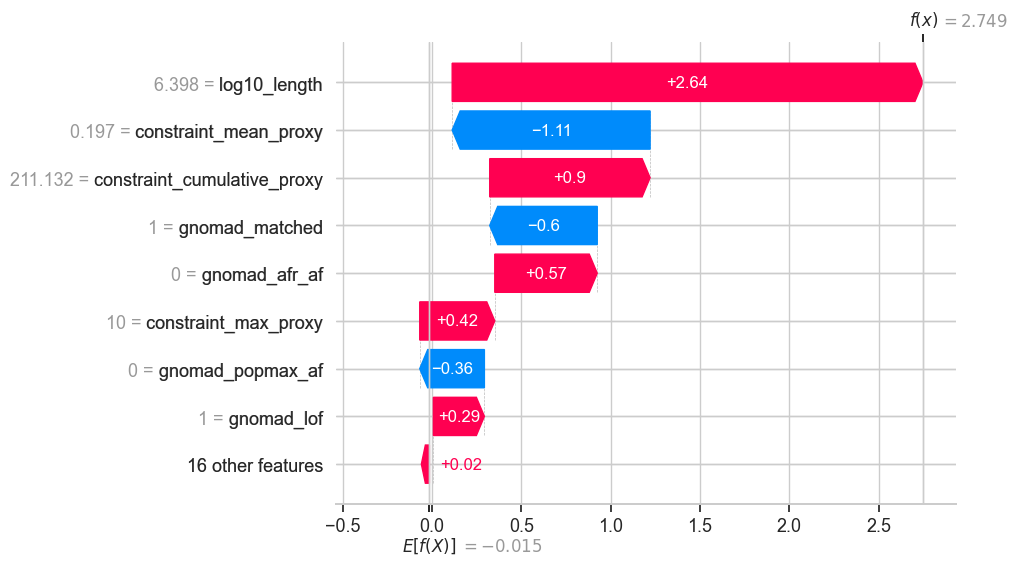


Candidate #2: SNF2.INV.INTERGENIC_VUS | Pathogenicity Score: 0.5408 | Tier 2 (Moderate-Risk / Uncertain)


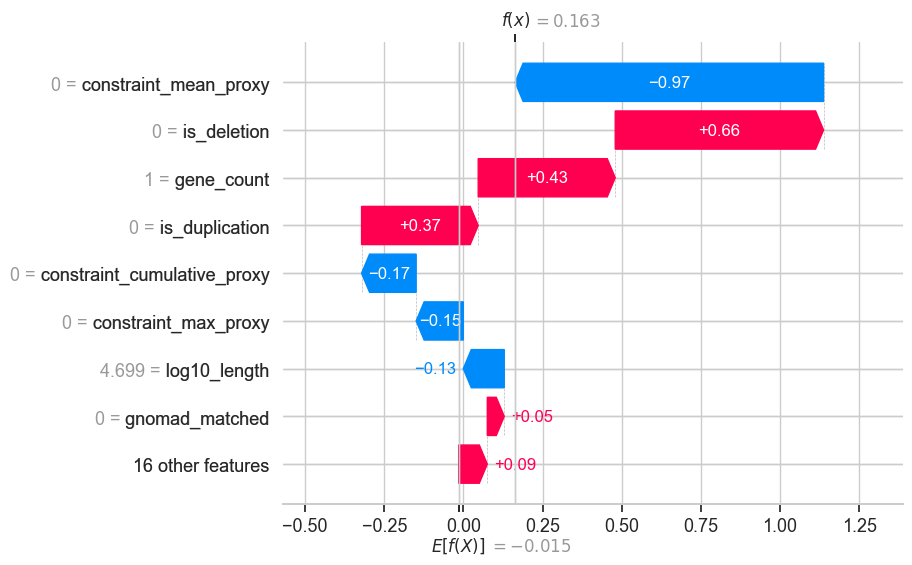


Candidate #3: SNF2.INS.INTRONIC_TOL | Pathogenicity Score: 0.5186 | Tier 2 (Moderate-Risk / Uncertain)


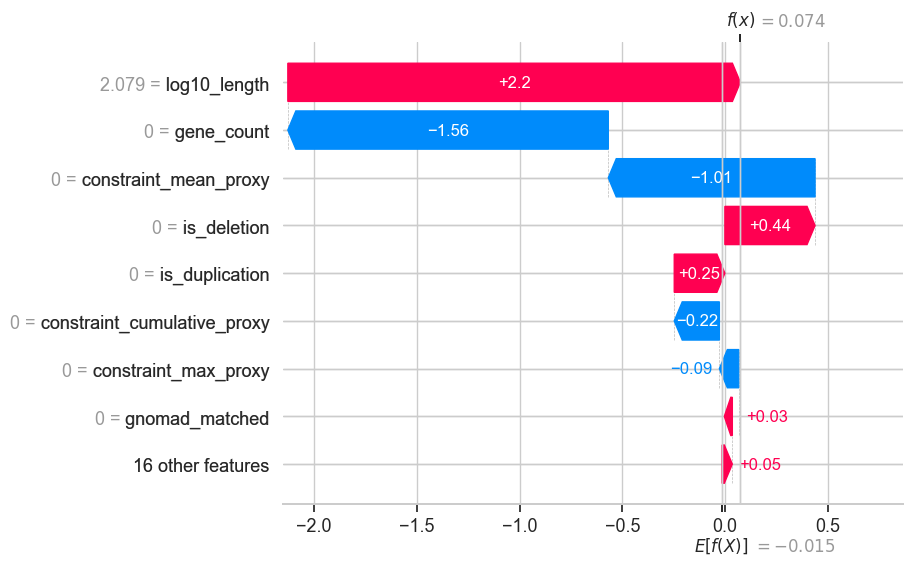

In [6]:
visualizer = SHAPVisualizer()

# Generate and display waterfall plots for top candidate variants
top_k = min(3, len(df_prioritized))
for rank in range(top_k):
    row = df_prioritized.iloc[rank]
    var_id = row['var_id']
    score = row['pathogenicity_score']
    tier = row['priority_tier']
    
    print(f"\nCandidate #{rank+1}: {var_id} | Pathogenicity Score: {score:.4f} | {tier}")
    
    feat_dict = {col: float(row.get(col, 0.0)) for col in visualizer.feature_cols}
    X_single = pd.DataFrame([feat_dict])
    shap_vals = visualizer.explainer(X_single)[0]
    
    plt.figure(figsize=(9, 4.5))
    shap.plots.waterfall(shap_vals, max_display=9, show=True)


## 6. Generate Clinical Reports (HTML, CSV, Annotated VCF)

In [7]:
shap_images_b64 = []
for rank in range(min(4, len(df_prioritized))):
    shap_images_b64.append(visualizer.generate_waterfall(df_prioritized.iloc[rank]))

out_dir = resolve_path("reports/sample_patient_report")
os.makedirs(out_dir, exist_ok=True)

reporter = ClinicalReporter(df_prioritized, sample_name=sample_id, top_shap_images=shap_images_b64)

html_path = os.path.join(out_dir, "clinical_report.html")
csv_path = os.path.join(out_dir, "ranked_variants.csv")
vcf_path = os.path.join(out_dir, f"{sample_id}.prioritized.vcf")

reporter.generate_html_report(html_path)
reporter.save_csv(csv_path)
reporter.save_annotated_vcf(vcf_input_path, vcf_path)

print(f"\nAll clinical deliverables exported successfully to: {out_dir}")


Saved interactive HTML report to: ..\reports/sample_patient_report\clinical_report.html
Saved ranked CSV report to: ..\reports/sample_patient_report\ranked_variants.csv
Saved annotated VCF to: ..\reports/sample_patient_report\Patient_HG002_LongRead.prioritized.vcf

All clinical deliverables exported successfully to: ..\reports/sample_patient_report
